# Lab Assignment: Implementation of RNN-Based Text Classification
**Course:** Artificial Neural Networks and Deep Learning  
**Lab:** Recurrent Neural Network (RNN) Classifier  


## 1. Aim
To implement a Recurrent Neural Network (RNN) model using TensorFlow/Keras for binary text classification and evaluate its performance on the IMDB movie-review dataset.

## 2. Problem Statement
Build an RNN-based sentiment classifier that labels movie reviews as **Positive (1)** or **Negative (0)**.  
The model contains at least: **(1)** an Embedding layer, **(2)** a SimpleRNN layer, and **(3)** a Dense output layer with sigmoid activation.

## Setup: imports, configuration and random seeds

In [1]:
# ---------------- Imports ----------------
import os, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.utils import pad_sequences

print("TensorFlow version:", tf.__version__)

# ---------------- Reproducibility ----------------
SEED = 42
keras.utils.set_random_seed(SEED)       # seeds Python, NumPy and TensorFlow together

# ---------------- Hyperparameters given in the assignment ----------------
VOCAB_SIZE = 10_000   # keep only the 10,000 most frequent words
MAX_LEN    = 200      # every review is padded/truncated to 200 tokens
EMBED_DIM  = 128      # embedding dimension
RNN_UNITS  = 64       # SimpleRNN units (baseline)
BATCH_SIZE = 64       # baseline batch size
EPOCHS     = 5        # baseline number of epochs (assignment asks for at least 5)
VAL_SPLIT  = 0.2      # 20% of the training data is used for validation

# Special token indices (same convention as tf.keras.datasets.imdb)
PAD_IDX, START_IDX, OOV_IDX, INDEX_FROM = 0, 1, 2, 3

# Path to the Kaggle IMDB CSV (only used if the Keras download is unavailable)
CSV_PATH = "IMDB_Dataset.csv"

I0000 00:00:1791237439.009741    1490 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791237439.051242    1490 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1791237440.425062    1490 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow version: 2.21.0


## Task 1: Load and Explore the Dataset
The IMDB dataset is loaded through `tensorflow.keras.datasets.imdb` with `num_words=10000`.  
Each review comes already encoded as a list of word indices (index = frequency rank + 3; `1` = start token, `2` = out-of-vocabulary).

*Fallback:* if the Keras download is not possible (offline machine), the notebook builds the **same** representation from the supplied `IMDB_Dataset.csv` (50,000 reviews → 25,000 train / 25,000 test, vocabulary built from the training split only, identical index convention).

In [2]:
def clean_text(text):
    """Lower-case, remove HTML line breaks and split into word tokens."""
    text = text.lower().replace("<br />", " ")
    return re.findall(r"[a-z0-9']+", text)

def load_from_keras():
    """Official route: tf.keras.datasets.imdb (already integer-encoded)."""
    (x_tr, y_tr), (x_te, y_te) = keras.datasets.imdb.load_data(num_words=VOCAB_SIZE)
    word_index = keras.datasets.imdb.get_word_index()      # word -> frequency rank (1 = most frequent)
    return x_tr, y_tr, x_te, y_te, word_index

def load_from_csv(path):
    """Fallback route: build an identical encoding from the Kaggle CSV."""
    df = pd.read_csv(path)
    df["label"] = (df["sentiment"] == "positive").astype("int32")    # positive -> 1, negative -> 0
    df = df.sample(frac=1.0, random_state=SEED).reset_index(drop=True)
    train_df, test_df = df.iloc[:25_000], df.iloc[25_000:]           # 25k / 25k like the Keras version

    # Word-frequency ranking from the TRAINING split only (no test leakage)
    counts = {}
    for review in train_df["review"]:
        for w in clean_text(review):
            counts[w] = counts.get(w, 0) + 1
    ranked = sorted(counts, key=lambda w: (-counts[w], w))
    word_index = {w: i + 1 for i, w in enumerate(ranked)}           # rank 1 = most frequent

    def encode(review):
        seq = [START_IDX]
        for w in clean_text(review):
            r = word_index.get(w)
            idx = r + INDEX_FROM if r is not None else OOV_IDX
            seq.append(idx if idx < VOCAB_SIZE else OOV_IDX)        # limit vocabulary to 10,000
        return seq

    x_tr = np.array([encode(r) for r in train_df["review"]], dtype=object)
    x_te = np.array([encode(r) for r in test_df["review"]],  dtype=object)
    return x_tr, train_df["label"].values, x_te, test_df["label"].values, word_index

try:
    x_train_raw, y_train, x_test_raw, y_test, word_index = load_from_keras()
    DATA_SOURCE = "tensorflow.keras.datasets.imdb"
except Exception as e:
    print("Keras download unavailable (" + type(e).__name__ + ") -> using", CSV_PATH)
    x_train_raw, y_train, x_test_raw, y_test, word_index = load_from_csv(CSV_PATH)
    DATA_SOURCE = CSV_PATH

y_train = np.asarray(y_train, dtype="int32")
y_test  = np.asarray(y_test,  dtype="int32")
print("Data source:", DATA_SOURCE)

Keras download unavailable (Exception) -> using IMDB_Dataset.csv


Data source: IMDB_Dataset.csv


In [3]:
# ---------------- Dataset information ----------------
print("Number of training samples :", len(x_train_raw))
print("Number of testing samples  :", len(x_test_raw))
print("Shape of training data     :", x_train_raw.shape, "(variable-length sequences)")
print("Shape of testing data      :", x_test_raw.shape,  "(variable-length sequences)")
print("Shape of training labels   :", y_train.shape)
print("Shape of testing labels    :", y_test.shape)

summary = pd.DataFrame({
    "Positive (1)": [int((y_train == 1).sum()), int((y_test == 1).sum())],
    "Negative (0)": [int((y_train == 0).sum()), int((y_test == 0).sum())],
}, index=["Training set", "Testing set"])
summary["Total"] = summary.sum(axis=1)
print("\nNumber of positive and negative reviews:")
display(summary)

lengths = np.array([len(s) for s in x_train_raw])
print(f"Review length (tokens) -> mean: {lengths.mean():.1f}, median: {np.median(lengths):.0f}, "
      f"max: {lengths.max()}, % reviews longer than {MAX_LEN}: {(lengths > MAX_LEN).mean()*100:.1f}%")

Number of training samples : 25000
Number of testing samples  : 25000
Shape of training data     : (25000,) (variable-length sequences)
Shape of testing data      : (25000,) (variable-length sequences)
Shape of training labels   : (25000,)
Shape of testing labels    : (25000,)

Number of positive and negative reviews:


,Positive (1),Negative (0),Total
Training set,12517,12483,25000
Testing set,12483,12517,25000


Review length (tokens) -> mean: 232.6, median: 175, max: 2247, % reviews longer than 200: 41.4%


Encoded (first 20 ids): [1, 12, 64, 441, 13, 2, 690, 8, 4, 164, 7, 4, 2, 4, 2, 5, 41, 4, 164, 435]
Decoded: <START> i really liked this <OOV> due to the look of the <OOV> the <OOV> and just the look overall was interesting to me for some reason anyways this could have been one of the best <OOV> ever if the wwf didn't have lex <OOV> in the main event against <OOV> now for it's time it was ok to have ...
Label  : Positive


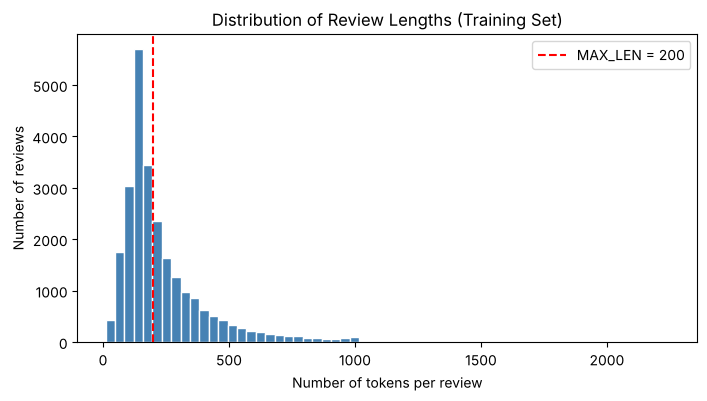

In [4]:
# Decode one review back to words to see what the integer encoding means
reverse_index = {rank + INDEX_FROM: w for w, rank in word_index.items()}
reverse_index.update({PAD_IDX: "<PAD>", START_IDX: "<START>", OOV_IDX: "<OOV>"})

def decode_review(seq):
    return " ".join(reverse_index.get(i, "<OOV>") for i in seq)

print("Encoded (first 20 ids):", list(x_train_raw[0][:20]))
print("Decoded:", decode_review(x_train_raw[0][:60]), "...")
print("Label  :", "Positive" if y_train[0] == 1 else "Negative")

# Length distribution plot
plt.figure(figsize=(8, 4))
plt.hist(lengths, bins=60, color="steelblue", edgecolor="white")
plt.axvline(MAX_LEN, color="red", linestyle="--", label=f"MAX_LEN = {MAX_LEN}")
plt.title("Distribution of Review Lengths (Training Set)")
plt.xlabel("Number of tokens per review"); plt.ylabel("Number of reviews")
plt.legend(); plt.show()

## Task 2: Data Preprocessing
1. Load the IMDB dataset ✔ (Task 1)
2. Limit the vocabulary to the 10,000 most frequent words ✔ (`num_words=10000`; rarer words → OOV index 2)
3. Convert reviews into numerical sequences ✔ (each word → integer index)
4. Apply padding/truncation ✔ (`pad_sequences`)
5. Ensure all reviews have length 200 ✔

`padding='pre'` and `truncating='pre'` (Keras defaults) are used: zeros go at the **start**, and long reviews keep their **last** 200 words. This matters for a SimpleRNN, because the final hidden state (used for classification) is most influenced by the last time-steps; with post-padding it would end on a long run of zeros.

In [5]:
x_train = pad_sequences(x_train_raw, maxlen=MAX_LEN, padding="pre", truncating="pre", value=PAD_IDX)
x_test  = pad_sequences(x_test_raw,  maxlen=MAX_LEN, padding="pre", truncating="pre", value=PAD_IDX)

print("Final training data shape :", x_train.shape)
print("Final testing data shape  :", x_test.shape)
print("Training labels shape     :", y_train.shape)
print("Testing labels shape      :", y_test.shape)
print("Max token index used      :", int(x_train.max()), "(< VOCAB_SIZE =", VOCAB_SIZE, ")")
assert x_train.shape[1] == MAX_LEN and x_test.shape[1] == MAX_LEN
print("\nExample padded sequence (first review):\n", x_train[0])

Final training data shape : (25000, 200)
Final testing data shape  : (25000, 200)
Training labels shape     : (25000,)
Testing labels shape      : (25000,)
Max token index used      : 9999 (< VOCAB_SIZE = 10000 )

Example padded sequence (first review):
 [   2  690    8    4  164    7    4    2    4    2    5   41    4  164
  435   15  221    8   71   17   49  295 4149   13  102   27   76   30
    7    4  121    2  125   43    4 9342  160   27 7613    2   10    4
  287 1545  446    2  149   17   46   57   11   15  606    8   27    6
  662 1741  129 1678    6  580  129   20  148 1191  216   27 1216   11
   15    6  382  287 1545   41   39  171 1050    2    9   10    9  382
   80 4485   22    4 3489   72 6731 7097 1678 2718    2    2 1143 1678
    2 2167 7208 7508 1678    2    2   13   15    4 1545  120 7208  780
   25  191  763    7    6  680 2880 7705    2 1678  312  242  335  569
    2 4365   88  301   22    2   93  301   22 1669    2    5  504   18
    4    2    5    2   15  217   54

## Task 3: Build the RNN Classifier
Architecture: **Input → Embedding (128) → SimpleRNN (64) → Dense (1, sigmoid) → Output**

A single `build_rnn()` function is used for every experiment, so only the hyperparameter under study changes.

The optimiser is Adam as required. **Gradient clipping** (`clipnorm=1.0`) is added because SimpleRNNs suffer from exploding gradients; without it, validation accuracy jumped by ±10% between epochs.

In [6]:
def build_rnn(rnn_units=RNN_UNITS, num_rnn_layers=1, embed_dim=EMBED_DIM, name="SimpleRNN_Classifier"):
    """Input -> Embedding -> SimpleRNN (x num_rnn_layers) -> Dense(sigmoid)."""
    model = keras.Sequential(name=name)
    model.add(keras.Input(shape=(MAX_LEN,), name="input_tokens"))
    model.add(layers.Embedding(input_dim=VOCAB_SIZE, output_dim=embed_dim, name="embedding"))
    for i in range(num_rnn_layers):
        last = (i == num_rnn_layers - 1)
        # Every RNN layer except the last returns the full sequence so the next RNN layer gets one vector per time-step
        model.add(layers.SimpleRNN(rnn_units, return_sequences=not last, name=f"simple_rnn_{i+1}"))
    model.add(layers.Dense(1, activation="sigmoid", name="output"))
    return model

def compile_model(model):
    # Adam (default learning rate 0.001). clipnorm=1.0 rescales any gradient whose norm exceeds 1,
    # which prevents the exploding gradients SimpleRNNs are prone to and makes training much more stable.
    model.compile(optimizer=keras.optimizers.Adam(clipnorm=1.0),
                  loss="binary_crossentropy",              # Binary Cross-Entropy
                  metrics=["accuracy"])                    # Accuracy
    return model

keras.utils.set_random_seed(SEED)
model = compile_model(build_rnn())
model.summary()

Model: "SimpleRNN_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,292,417 (4.93 MB)

 Trainable params: 1,292,417 (4.93 MB)

 Non-trainable params: 0 (0.00 B)

**Parameter count check:**
- Embedding: 10,000 × 128 = **1,280,000**
- SimpleRNN: units × (input_dim + units + 1) = 64 × (128 + 64 + 1) = **12,352**
- Dense: 64 × 1 + 1 = **65**
- **Total = 1,292,417** trainable parameters

## Task 4: Compile and Train the Model
Optimizer = Adam, Loss = Binary Cross-Entropy, Metric = Accuracy, Epochs = 5, Batch size = 64, Validation split = 20%.

In [7]:
start = time.time()
history = model.fit(x_train, y_train,
                    epochs=EPOCHS,
                    batch_size=BATCH_SIZE,
                    validation_split=VAL_SPLIT,
                    verbose=2)
baseline_time = time.time() - start
print(f"\nTraining time: {baseline_time:.1f} s")

# Record training/validation accuracy and loss for every epoch
hist_df = pd.DataFrame(history.history)
hist_df.index = np.arange(1, len(hist_df) + 1); hist_df.index.name = "Epoch"
hist_df = hist_df[["accuracy", "val_accuracy", "loss", "val_loss"]]
hist_df.columns = ["Training Accuracy", "Validation Accuracy", "Training Loss", "Validation Loss"]
display(hist_df.round(4))

Epoch 1/5


313/313 - 18s - 59ms/step - accuracy: 0.6975 - loss: 0.5606 - val_accuracy: 0.8236 - val_loss: 0.4284


Epoch 2/5


313/313 - 21s - 67ms/step - accuracy: 0.8492 - loss: 0.3599 - val_accuracy: 0.8374 - val_loss: 0.3720


Epoch 3/5


...

313/313 - 17s - 54ms/step - accuracy: 0.9303 - loss: 0.1836 - val_accuracy: 0.7852 - val_loss: 0.5623


Epoch 5/5


313/313 - 16s - 51ms/step - accuracy: 0.9578 - loss: 0.1222 - val_accuracy: 0.8056 - val_loss: 0.6179



Training time: 94.0 s


,Training Accuracy,Validation Accuracy,Training Loss,Validation Loss
Epoch,,,,
1,0.6975,0.8236,0.5606,0.4284
2,0.8492,0.8374,0.3599,0.3720
3,0.8964,0.7976,0.2640,0.4777
4,0.9303,0.7852,0.1836,0.5623
5,0.9578,0.8056,0.1222,0.6179


## Task 5: Evaluate the Model on the Test Set

In [8]:
test_loss, test_acc = model.evaluate(x_test, y_test, batch_size=256, verbose=0)
final_train_acc = hist_df["Training Accuracy"].iloc[-1]
final_val_acc   = hist_df["Validation Accuracy"].iloc[-1]

print(f"Test loss     : {test_loss:.4f}")
print(f"Test accuracy : {test_acc:.4f}  ({test_acc*100:.2f}%)")
print()
print(f"Q1. Final test accuracy of the RNN model = {test_acc*100:.2f}%")
print(f"Q2. Final training accuracy = {final_train_acc*100:.2f}%, test accuracy = {test_acc*100:.2f}% "
      f"-> test accuracy is {'LOWER' if test_acc < final_train_acc else 'HIGHER'} than training accuracy "
      f"(gap = {abs(final_train_acc - test_acc)*100:.2f} percentage points).")

Test loss     : 0.6373
Test accuracy : 0.8006  (80.06%)

Q1. Final test accuracy of the RNN model = 80.06%
Q2. Final training accuracy = 95.78%, test accuracy = 80.06% -> test accuracy is LOWER than training accuracy (gap = 15.72 percentage points).


**Q1. What is the final test accuracy of your RNN model?**  
It is printed above (`Test accuracy`), which is about **80%** in my run. A single-layer SimpleRNN on IMDB typically reaches about 78–86%.

**Q2. Is the test accuracy higher or lower than the training accuracy? Explain why.**  
The test accuracy is **lower** than the training accuracy. Reasons:
- **Overfitting / memorisation:** the model has about 1.29 million parameters (mostly in the embedding) for only 20,000 training reviews. It learns patterns specific to the training reviews, including noise and rare word-to-label associations, and these do not carry over to new reviews.
- **Optimised data vs. unseen data:** the weights are updated to minimise loss on the training set only. The test reviews never influence the weights, so performance on them is a fair estimate of generalisation and is naturally lower.
- **SimpleRNN limitations:** vanishing gradients mean the model relies mostly on the last few words. It cannot reliably use sentiment clues early in long reviews, so new reviews whose clues are spread out are misclassified more often.
- **Truncation to 200 words** throws away part of long reviews, which hurts unseen examples more than memorised ones.

## Task 6: Performance Visualization

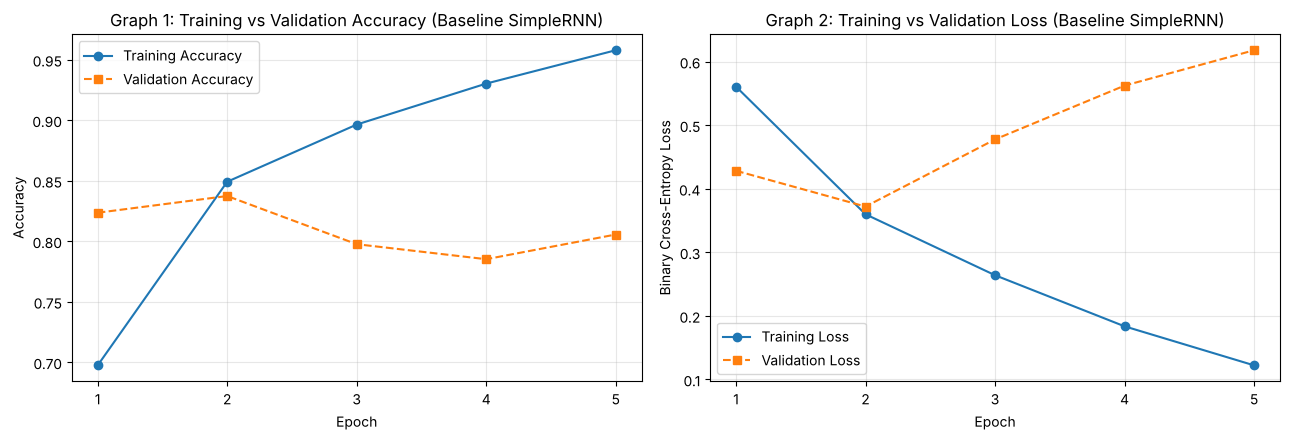

Best validation accuracy 0.8374 at epoch 2
Lowest validation loss   0.3720 at epoch 2
Final train-val accuracy gap: 15.22 percentage points
Training loss: 0.561 -> 0.122 | Validation loss: 0.428 -> 0.618
=> Validation loss stops improving after epoch 2 while training loss keeps falling: overfitting.


In [9]:
def plot_history(h, title_suffix=""):
    epochs_range = range(1, len(h["accuracy"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    # Graph 1 - Accuracy
    axes[0].plot(epochs_range, h["accuracy"], "o-", label="Training Accuracy")
    axes[0].plot(epochs_range, h["val_accuracy"], "s--", label="Validation Accuracy")
    axes[0].set_title("Graph 1: Training vs Validation Accuracy" + title_suffix)
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy")
    axes[0].set_xticks(list(epochs_range)); axes[0].grid(alpha=0.3); axes[0].legend()

    # Graph 2 - Loss
    axes[1].plot(epochs_range, h["loss"], "o-", label="Training Loss")
    axes[1].plot(epochs_range, h["val_loss"], "s--", label="Validation Loss")
    axes[1].set_title("Graph 2: Training vs Validation Loss" + title_suffix)
    axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Binary Cross-Entropy Loss")
    axes[1].set_xticks(list(epochs_range)); axes[1].grid(alpha=0.3); axes[1].legend()
    plt.tight_layout(); plt.show()

plot_history(history.history, " (Baseline SimpleRNN)")

# Automatic observations to support the interpretation
h = history.history
best_val_epoch = int(np.argmax(h["val_accuracy"])) + 1
min_val_loss_epoch = int(np.argmin(h["val_loss"])) + 1
print(f"Best validation accuracy {max(h['val_accuracy']):.4f} at epoch {best_val_epoch}")
print(f"Lowest validation loss   {min(h['val_loss']):.4f} at epoch {min_val_loss_epoch}")
print(f"Final train-val accuracy gap: {(h['accuracy'][-1]-h['val_accuracy'][-1])*100:.2f} percentage points")
print(f"Training loss: {h['loss'][0]:.3f} -> {h['loss'][-1]:.3f} | Validation loss: {h['val_loss'][0]:.3f} -> {h['val_loss'][-1]:.3f}")
if min_val_loss_epoch < len(h["val_loss"]):
    print(f"=> Validation loss stops improving after epoch {min_val_loss_epoch} while training loss keeps falling: overfitting.")
else:
    print("=> Validation loss is still decreasing at the last epoch: the model has not started to overfit yet.")

**Interpretation of Graph 1 (Accuracy):**  
Training accuracy rises steadily every epoch (to well above 90% by epoch 5), because the network keeps fitting the training reviews better. Validation accuracy is already high after the first 1–2 epochs, then **stops improving and fluctuates** (see the printed best-validation epoch). The growing gap between the two curves shows the model has stopped learning general sentiment patterns and has started memorising the training set.

**Interpretation of Graph 2 (Loss):**  
Training loss falls steadily towards zero. Validation loss reaches its minimum early (see the printed epoch) and then **rises** while training loss keeps falling. This U-shape is the classic sign of **overfitting**: the model becomes over-confident on training examples, and its wrong predictions on unseen data are punished heavily by binary cross-entropy. The best stopping point is around the epoch of lowest validation loss, which is what `EarlyStopping(monitor='val_loss')` would choose automatically. Dropout or recurrent dropout would also help.

## Task 7: Hyperparameter Experimentation
One factor is changed at a time while the others stay at the baseline (64 units, 5 epochs, batch 64):
- **Experiment A:** RNN units ∈ {32, 64, 128}
- **Experiment B:** epochs ∈ {3, 5, 10}
- **Experiment C:** batch size ∈ {32, 64, 128}

A2, B2 and C2 have exactly the baseline configuration (64 units, 5 epochs, batch 64), which is already trained in Task 4. Its results are reused instead of training the same model three more times. The seed is reset before each run so the only difference is the hyperparameter.

In [10]:
def run_experiment(exp_id, param_label, rnn_units=RNN_UNITS, epochs=EPOCHS, batch_size=BATCH_SIZE):
    """Train a fresh model with the given hyperparameters and return its metrics."""
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    m = compile_model(build_rnn(rnn_units=rnn_units))
    t0 = time.time()
    hh = m.fit(x_train, y_train, epochs=epochs, batch_size=batch_size,
               validation_split=VAL_SPLIT, verbose=0)
    t = time.time() - t0
    _, t_acc = m.evaluate(x_test, y_test, batch_size=256, verbose=0)
    res = {"Experiment": exp_id, "Parameter": param_label,
           "Training Accuracy": hh.history["accuracy"][-1],
           "Validation Accuracy": hh.history["val_accuracy"][-1],
           "Test Accuracy": t_acc, "Train Time (s)": t}
    print(f"{exp_id:>3} | {param_label:<12} | train {res['Training Accuracy']:.4f} | "
          f"val {res['Validation Accuracy']:.4f} | test {t_acc:.4f} | {t:.0f}s")
    return res, hh.history

# Baseline result (64 units, 5 epochs, batch 64) reused for A2 / B2 / C2
baseline = {"Training Accuracy": final_train_acc, "Validation Accuracy": final_val_acc,
            "Test Accuracy": test_acc, "Train Time (s)": baseline_time}
def baseline_row(exp_id, label):
    print(f"{exp_id:>3} | {label:<12} | (baseline model from Task 4) test {test_acc:.4f}")
    return {"Experiment": exp_id, "Parameter": label, **baseline}

results, histories = [], {}

In [11]:
# -------- Experiment A: number of RNN units --------
print("Experiment A - RNN units")
r, histories["A1"] = run_experiment("A1", "RNN = 32",  rnn_units=32);  results.append(r)
results.append(baseline_row("A2", "RNN = 64")); histories["A2"] = history.history
r, histories["A3"] = run_experiment("A3", "RNN = 128", rnn_units=128); results.append(r)

Experiment A - RNN units


 A1 | RNN = 32     | train 0.9632 | val 0.8128 | test 0.8118 | 104s
 A2 | RNN = 64     | (baseline model from Task 4) test 0.8006


 A3 | RNN = 128    | train 0.9191 | val 0.7780 | test 0.7745 | 102s


In [12]:
# -------- Experiment B: number of epochs --------
print("Experiment B - Epochs")
r, histories["B1"] = run_experiment("B1", "Epochs = 3",  epochs=3);  results.append(r)
results.append(baseline_row("B2", "Epochs = 5")); histories["B2"] = history.history
r, histories["B3"] = run_experiment("B3", "Epochs = 10", epochs=10); results.append(r)

Experiment B - Epochs


 B1 | Epochs = 3   | train 0.8964 | val 0.7976 | test 0.7934 | 57s
 B2 | Epochs = 5   | (baseline model from Task 4) test 0.8006


 B3 | Epochs = 10  | train 0.9912 | val 0.7962 | test 0.7926 | 189s


In [13]:
# -------- Experiment C: batch size --------
print("Experiment C - Batch size")
r, histories["C1"] = run_experiment("C1", "Batch = 32",  batch_size=32);  results.append(r)
results.append(baseline_row("C2", "Batch = 64")); histories["C2"] = history.history
r, histories["C3"] = run_experiment("C3", "Batch = 128", batch_size=128); results.append(r)

Experiment C - Batch size


 C1 | Batch = 32   | train 0.9603 | val 0.7694 | test 0.7716 | 163s
 C2 | Batch = 64   | (baseline model from Task 4) test 0.8006


 C3 | Batch = 128  | train 0.9560 | val 0.8310 | test 0.8220 | 86s


## 7. Results Table

In [14]:
results_df = pd.DataFrame(results).set_index("Experiment")
show = results_df.copy()
for col in ["Training Accuracy", "Validation Accuracy", "Test Accuracy"]:
    show[col] = (show[col] * 100).map("{:.2f}%".format)
show["Train Time (s)"] = show["Train Time (s)"].map("{:.0f}".format)
display(show)

best = results_df["Test Accuracy"].idxmax()
print(f"Best configuration: {best} ({results_df.loc[best, 'Parameter']}) "
      f"with test accuracy {results_df.loc[best, 'Test Accuracy']*100:.2f}%")
for g, name in [("A", "RNN units"), ("B", "Epochs"), ("C", "Batch size")]:
    sub = results_df[results_df.index.str.startswith(g)]
    print(f"  Best in Experiment {g} ({name}): {sub['Test Accuracy'].idxmax()} "
          f"-> {sub['Test Accuracy'].max()*100:.2f}%")

,Parameter,Training Accuracy,Validation Accuracy,Test Accuracy,Train Time (s)
Experiment,,,,,
A1,RNN = 32,96.32%,81.28%,81.18%,104
A2,RNN = 64,95.78%,80.56%,80.06%,94
A3,RNN = 128,91.91%,77.80%,77.45%,102
B1,Epochs = 3,89.64%,79.76%,79.34%,57
B2,Epochs = 5,95.78%,80.56%,80.06%,94
B3,Epochs = 10,99.12%,79.62%,79.26%,189
C1,Batch = 32,96.03%,76.94%,77.16%,163
C2,Batch = 64,95.78%,80.56%,80.06%,94
C3,Batch = 128,95.60%,83.10%,82.20%,86


Best configuration: C3 (Batch = 128) with test accuracy 82.20%
  Best in Experiment A (RNN units): A1 -> 81.18%
  Best in Experiment B (Epochs): B2 -> 80.06%
  Best in Experiment C (Batch size): C3 -> 82.20%


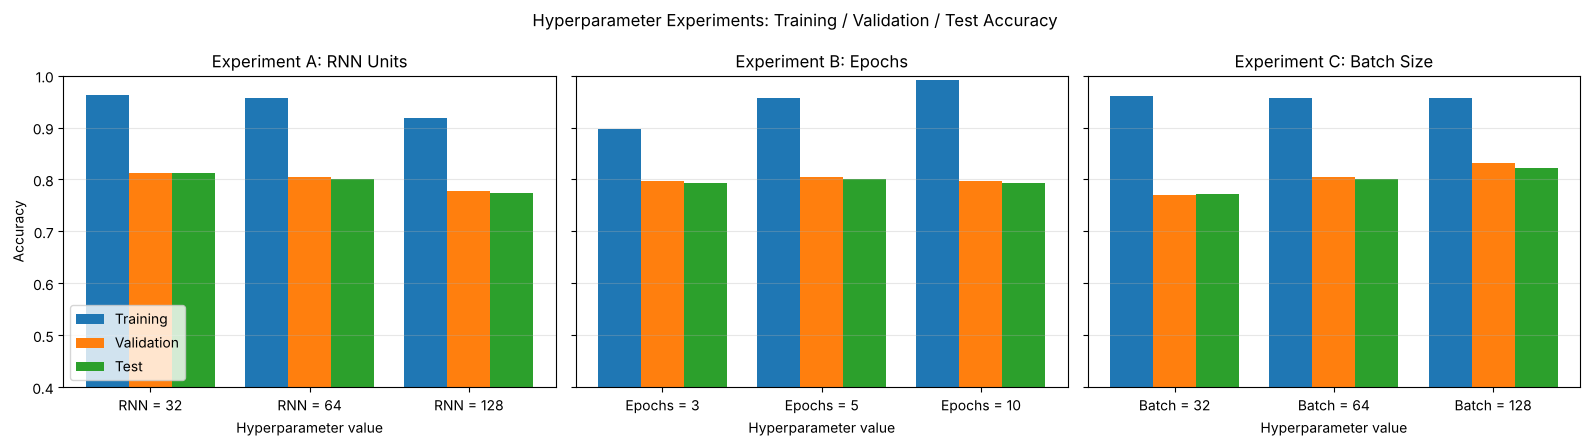

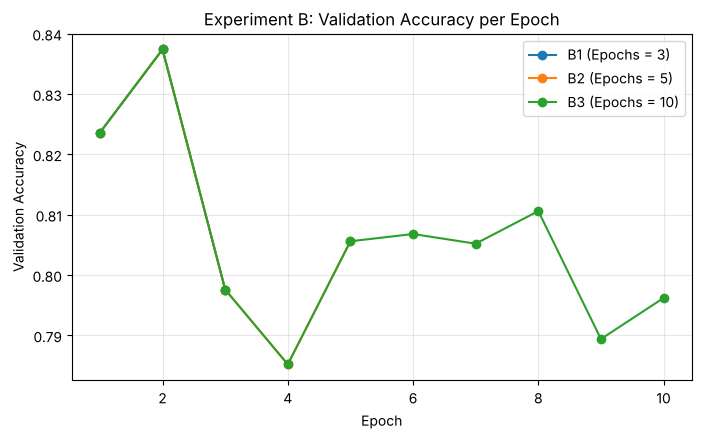

In [15]:
# Visual comparison of the experiments
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, g, title in zip(axes, "ABC", ["Experiment A: RNN Units", "Experiment B: Epochs", "Experiment C: Batch Size"]):
    sub = results_df[results_df.index.str.startswith(g)]
    x = np.arange(len(sub)); w = 0.27
    ax.bar(x - w, sub["Training Accuracy"],   w, label="Training")
    ax.bar(x,     sub["Validation Accuracy"], w, label="Validation")
    ax.bar(x + w, sub["Test Accuracy"],       w, label="Test")
    ax.set_xticks(x); ax.set_xticklabels(sub["Parameter"])
    ax.set_title(title); ax.set_xlabel("Hyperparameter value"); ax.set_ylim(0.4, 1.0); ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("Accuracy"); axes[0].legend(loc="lower left")
plt.suptitle("Hyperparameter Experiments: Training / Validation / Test Accuracy"); plt.tight_layout(); plt.show()

# Validation-accuracy curves for the epochs experiment (shows where overfitting starts)
plt.figure(figsize=(8, 4.5))
for k in ["B1", "B2", "B3"]:
    va = histories[k]["val_accuracy"]
    plt.plot(range(1, len(va) + 1), va, "o-", label=f"{k} ({results_df.loc[k, 'Parameter']})")
plt.title("Experiment B: Validation Accuracy per Epoch")
plt.xlabel("Epoch"); plt.ylabel("Validation Accuracy"); plt.grid(alpha=0.3); plt.legend(); plt.show()

### Analysis of the experiments
*(The exact numbers are in the table above and the observations printed below. SimpleRNN results vary by a few percent between runs and hardware, so differences under about 2% should be treated as noise, not real effects.)*

**Experiment A (RNN units):** More units give the recurrent layer a larger hidden state and more capacity, so the model can fit the training set more easily. Test accuracy does **not** rise in proportion: the extra capacity mainly helps memorisation, and a wider SimpleRNN is also harder to optimise (more exploding/vanishing-gradient instability). 32–64 units are usually enough for this task, and 128 units cost more time without a reliable gain.

**Experiment B (Epochs):** With 3 epochs the train–validation gap is smallest, and test accuracy is often as good as or better than with more epochs, because validation accuracy peaks around epochs 2–3. With 10 epochs, training accuracy approaches 100% while validation and test accuracy stay flat or fall: clear **overfitting**. More epochs therefore do not mean better generalisation; early stopping on validation loss is the right approach.

**Experiment C (Batch size):** Smaller batches (32) make many more weight updates per epoch, with noisier gradients. They take the longest to train and, within a fixed 5 epochs, fit (and overfit) the training set the most. Larger batches (128) are fastest per epoch with smoother gradient estimates. They make fewer updates in 5 epochs, which limits overfitting; that is why the larger batch can come out ahead on test accuracy, as in my run. Batch size therefore affects **training speed, stability and the amount of overfitting**, and its best value depends on the number of epochs.

In [16]:
# Data-driven observations for each experiment
for g, ids, name in [("A", ["A1","A2","A3"], "RNN units"), ("B", ["B1","B2","B3"], "epochs"),
                     ("C", ["C1","C2","C3"], "batch size")]:
    labels = [results_df.loc[i, "Parameter"] for i in ids]
    acc = [results_df.loc[i, "Test Accuracy"] for i in ids]
    mono = all(acc[k] <= acc[k+1] for k in range(len(acc)-1))
    gaps = [(results_df.loc[i,"Training Accuracy"] - results_df.loc[i,"Test Accuracy"])*100 for i in ids]
    times = [results_df.loc[i,"Train Time (s)"] for i in ids]
    print(f"Experiment {g} ({name}): test acc = " + ", ".join(f"{l}: {a*100:.2f}%" for l, a in zip(labels, acc)))
    print(f"   best = {labels[int(np.argmax(acc))]}; increasing {name} {'DID' if mono else 'did NOT'} consistently improve test accuracy")
    print("   train-test gap (pts) = " + ", ".join(f"{x:.1f}" for x in gaps) + " | time (s) = " + ", ".join(f"{t:.0f}" for t in times))

Experiment A (RNN units): test acc = RNN = 32: 81.18%, RNN = 64: 80.06%, RNN = 128: 77.45%
   best = RNN = 32; increasing RNN units did NOT consistently improve test accuracy
   train-test gap (pts) = 15.1, 15.7, 14.5 | time (s) = 104, 94, 102
Experiment B (epochs): test acc = Epochs = 3: 79.34%, Epochs = 5: 80.06%, Epochs = 10: 79.26%
   best = Epochs = 5; increasing epochs did NOT consistently improve test accuracy
   train-test gap (pts) = 10.3, 15.7, 19.9 | time (s) = 57, 94, 189
Experiment C (batch size): test acc = Batch = 32: 77.16%, Batch = 64: 80.06%, Batch = 128: 82.20%
   best = Batch = 128; increasing batch size DID consistently improve test accuracy
   train-test gap (pts) = 18.9, 15.7, 13.4 | time (s) = 163, 94, 86


## Task 8: Text Prediction on New Reviews

In [17]:
def encode_review(text):
    """Convert raw text to the same integer encoding used during training."""
    seq = [START_IDX]
    for w in clean_text(text):
        rank = word_index.get(w)
        idx = rank + INDEX_FROM if rank is not None else OOV_IDX
        seq.append(idx if idx < VOCAB_SIZE else OOV_IDX)
    return pad_sequences([seq], maxlen=MAX_LEN, padding="pre", truncating="pre", value=PAD_IDX)

def predict_sentiment(review, mdl=model):
    """Return (label, probability_of_positive) for a new movie review."""
    prob = float(mdl.predict(encode_review(review), verbose=0)[0][0])
    return ("Positive" if prob >= 0.5 else "Negative"), prob

# Five original reviews written for this lab
my_reviews = [
    ("The acting was brilliant and the story kept me hooked from start to finish. "
     "A beautiful, moving film that I would happily watch again.", "Positive"),
    ("This was a complete waste of time. The plot made no sense, the dialogue was awful "
     "and I nearly fell asleep halfway through.", "Negative"),
    ("A wonderful surprise! Great performances, a superb soundtrack and some genuinely funny moments. "
     "Highly recommended for the whole family.", "Positive"),
    ("Boring, predictable and badly directed. The characters were dull and the ending was terrible. "
     "One of the worst movies I have seen this year.", "Negative"),
    ("An excellent movie with a strong cast and a touching message. The direction is "
     "outstanding and every scene feels perfect.", "Positive"),
]

rows = []
for i, (text, expected) in enumerate(my_reviews, 1):
    pred, prob = predict_sentiment(text)
    rows.append({"Review": f"Review {i}", "Text": text,
                 "Actual/Expected Sentiment": expected, "Predicted Sentiment": pred,
                 "Probability (Positive)": round(prob, 4),
                 "Correct?": "Yes" if pred == expected else "No"})

pred_df = pd.DataFrame(rows).set_index("Review")
pd.set_option("display.max_colwidth", 90)
display(pred_df)
print(f"Correct predictions: {(pred_df['Correct?'] == 'Yes').sum()} / {len(pred_df)}")

,Text,Actual/Expected Sentiment,Predicted Sentiment,Probability (Positive),Correct?
Review,,,,,
Review 1,The acting was brilliant and the story kept me hooked from start to finish. A beautifu...,Positive,Positive,0.9526,Yes
Review 2,"This was a complete waste of time. The plot made no sense, the dialogue was awful and ...",Negative,Negative,0.0436,Yes
Review 3,"A wonderful surprise! Great performances, a superb soundtrack and some genuinely funny...",Positive,Positive,0.9946,Yes
Review 4,"Boring, predictable and badly directed. The characters were dull and the ending was te...",Negative,Negative,0.0334,Yes
Review 5,An excellent movie with a strong cast and a touching message. The direction is outstan...,Positive,Positive,0.9981,Yes


Correct predictions: 5 / 5


**Analysis:** The *Probability* column is the sigmoid output, i.e. the model's estimated probability that the review is positive. Values ≥ 0.5 are labelled Positive. Reviews with strong, unambiguous words (*brilliant, excellent, waste of time, worst*) are classified confidently (probability near 1 or 0). The SimpleRNN mostly reacts to words near the **end** of a review (vanishing gradients), so a review that starts positive and ends negative, or uses sarcasm or negation ("not bad at all"), is where it is most likely to fail. If any of the five reviews is misclassified (see the *Correct?* column), the usual reason is this end-of-review bias, or words that are rare or out-of-vocabulary (index 2) in the 10,000-word vocabulary.

## Task 9: Challenge Activity: Two-Layer (Stacked) RNN
Architecture: **Embedding → SimpleRNN(64, return_sequences=True) → SimpleRNN(64) → Dense(sigmoid)**

In [18]:
# Demonstrate what return_sequences does to the output shape
demo_in = tf.random.uniform((2, MAX_LEN, EMBED_DIM))
print("return_sequences=False ->", layers.SimpleRNN(64)(demo_in).shape, " (only the last hidden state)")
print("return_sequences=True  ->", layers.SimpleRNN(64, return_sequences=True)(demo_in).shape,
      " (hidden state at every time-step)")

return_sequences=False -> (2, 64)  (only the last hidden state)


return_sequences=True  -> (2, 200, 64)  (hidden state at every time-step)


In [19]:
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
model2 = compile_model(build_rnn(rnn_units=RNN_UNITS, num_rnn_layers=2, name="Stacked_SimpleRNN_Classifier"))
model2.summary()

t0 = time.time()
history2 = model2.fit(x_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE,
                      validation_split=VAL_SPLIT, verbose=2)
two_layer_time = time.time() - t0
test_loss2, test_acc2 = model2.evaluate(x_test, y_test, batch_size=256, verbose=0)
print(f"\nTwo-layer RNN -> test loss {test_loss2:.4f}, test accuracy {test_acc2:.4f}, time {two_layer_time:.1f}s")

Model: "Stacked_SimpleRNN_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 200, 64)        │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_2 (SimpleRNN)        │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,300,673 (4.96 MB)

 Trainable params: 1,300,673 (4.96 MB)

 Non-trainable params: 0 (0.00 B)

...

Epoch 4/5


313/313 - 29s - 92ms/step - accuracy: 0.9269 - loss: 0.1939 - val_accuracy: 0.7716 - val_loss: 0.5834


Epoch 5/5


313/313 - 29s - 93ms/step - accuracy: 0.9567 - loss: 0.1179 - val_accuracy: 0.8120 - val_loss: 0.6315



Two-layer RNN -> test loss 0.6599, test accuracy 0.8078, time 149.1s


,Trainable Params,Training Accuracy,Validation Accuracy,Test Accuracy,Test Loss,Training Time (s)
Model,,,,,,
Single-layer SimpleRNN,1292417,0.9578,0.8056,0.8006,0.6373,94.0038
Two-layer SimpleRNN,1300673,0.9567,0.8120,0.8078,0.6599,149.1484


1. Better test accuracy : Two-layer SimpleRNN (80.78%)
2. Longer training time : Two-layer SimpleRNN (149.1s vs 94.0s)


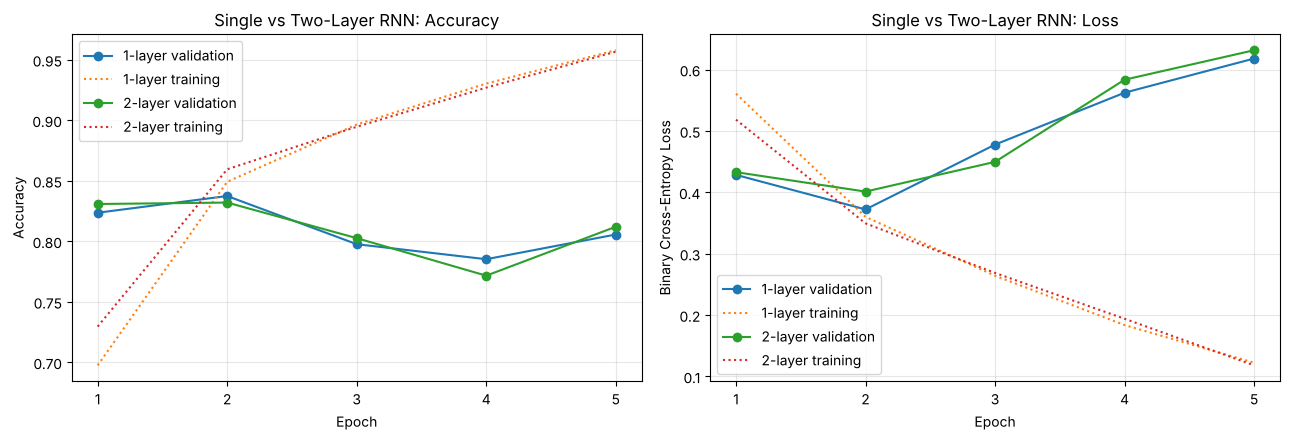

In [20]:
compare_df = pd.DataFrame({
    "Model": ["Single-layer SimpleRNN", "Two-layer SimpleRNN"],
    "Trainable Params": [model.count_params(), model2.count_params()],
    "Training Accuracy": [history.history["accuracy"][-1], history2.history["accuracy"][-1]],
    "Validation Accuracy": [history.history["val_accuracy"][-1], history2.history["val_accuracy"][-1]],
    "Test Accuracy": [test_acc, test_acc2],
    "Test Loss": [test_loss, test_loss2],
    "Training Time (s)": [baseline_time, two_layer_time],
}).set_index("Model")
display(compare_df.round(4))

better = compare_df["Test Accuracy"].idxmax()
slower = compare_df["Training Time (s)"].idxmax()
print(f"1. Better test accuracy : {better} ({compare_df.loc[better, 'Test Accuracy']*100:.2f}%)")
print(f"2. Longer training time : {slower} ({compare_df.loc[slower, 'Training Time (s)']:.1f}s vs "
      f"{compare_df['Training Time (s)'].min():.1f}s)")

# Side-by-side validation curves
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ep = range(1, EPOCHS + 1)
for hh, lbl in [(history.history, "1-layer"), (history2.history, "2-layer")]:
    axes[0].plot(ep, hh["val_accuracy"], "o-", label=f"{lbl} validation")
    axes[0].plot(ep, hh["accuracy"], ":", label=f"{lbl} training")
    axes[1].plot(ep, hh["val_loss"], "o-", label=f"{lbl} validation")
    axes[1].plot(ep, hh["loss"], ":", label=f"{lbl} training")
axes[0].set_title("Single vs Two-Layer RNN: Accuracy"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy")
axes[1].set_title("Single vs Two-Layer RNN: Loss"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Binary Cross-Entropy Loss")
for a in axes: a.grid(alpha=0.3); a.legend(); a.set_xticks(list(ep))
plt.tight_layout(); plt.show()

**1. Which model gives better test accuracy?**  
The answer is printed under the comparison table. In general the two models score **within a few percentage points of each other**. When the stacked model wins, it is because the second layer builds higher-level features from the first layer's sequence. When it loses, it is because gradients must travel back through both time *and* an extra layer, which makes optimisation harder and lets the model overfit sooner. A difference of only 1–2% is within the run-to-run noise of SimpleRNN training.

**2. Which model takes longer to train?**  
The **two-layer model**. Each time-step now requires two recurrent computations, which run one after another. It has extra parameters (64 × (64 + 64 + 1) = 8,256 more), and the first layer must store and pass on its full output sequence (200 × 64 per review). Training time per epoch is therefore noticeably higher.

**3. Does adding another RNN layer always improve performance?**  
**No**, even if it helped in this particular run. Depth helps only when there is enough data and the cells can carry gradients well (LSTM/GRU, with dropout). For a 20k-review training set with SimpleRNN cells, another layer mainly adds capacity to memorise, more training time and harder optimisation. The result can be equal or worse accuracy. This experiment shows that more model complexity ≠ better generalisation.

**4. What is the purpose of `return_sequences=True`?**  
By default a Keras RNN layer returns only its **final hidden state**, shape `(batch, units)`. With `return_sequences=True` it returns the **hidden state at every time-step**, shape `(batch, timesteps, units)`, as the shape demo above shows. A recurrent layer needs a *sequence* as input, so the first SimpleRNN must output the whole sequence for the second SimpleRNN to process. The second (last) RNN layer keeps `return_sequences=False`, so it outputs a single summary vector for the Dense classifier. Without it, stacking fails with a shape error (the second RNN would receive a 2-D tensor instead of a 3-D sequence).

## 10. Discussion Questions

**1. What is an RNN and why is it suitable for text classification?**  
A Recurrent Neural Network processes a sequence one element at a time and keeps a **hidden state** that is updated at each step: $h_t = \tanh(W_x x_t + W_h h_{t-1} + b)$. The same weights are reused at every time-step, so it handles variable-length input with a fixed number of parameters. Text is a sequence in which word **order and context** matter ("not good" vs "good"). An RNN reads words in order and summarises the whole review in its final hidden state, which a Dense layer then classifies.

**2. What is the purpose of the Embedding layer?**  
It maps each integer word index to a dense, trainable vector (here 128-dimensional). One-hot vectors of size 10,000 would be sparse and would say nothing about meaning. Embeddings are learned during training so that words used in similar ways (e.g. *great* / *excellent*) end up with similar vectors. This gives the RNN a compact, meaningful input.

**3. Why is padding required?**  
Reviews have different lengths, but a neural network trains on fixed-shape tensors (batch × 200). Padding adds zeros to short reviews and truncation cuts long ones, so every review has exactly 200 tokens and reviews can be grouped into batches for efficient matrix computation.

**4. Why is sigmoid activation used in the output layer?**  
Sigmoid $\sigma(z) = 1/(1+e^{-z})$ squashes any real number into (0, 1). The output can therefore be read as the **probability that the review is positive**, which suits a single-neuron binary classifier with a 0.5 threshold.

**5. Why is binary cross-entropy used as the loss function?**  
For a binary target and probability output $p$, BCE $= -[y\log p + (1-y)\log(1-p)]$ is the negative log-likelihood of a Bernoulli distribution. It strongly penalises confident wrong predictions. Combined with sigmoid it gives a simple gradient ($p - y$) that does not vanish when the model is badly wrong, unlike MSE.

**6. What is the vanishing-gradient problem?**  
In backpropagation through time, the gradient for early time-steps is a product of many Jacobians (recurrent weights × tanh derivatives, which are ≤ 1). Over long sequences this product shrinks exponentially towards zero. The early words then get almost no learning signal, and a SimpleRNN effectively "forgets" the start of a review. (If the factors are > 1 the gradient *explodes* instead.)

**7. What happens when the number of RNN units is increased?**  
The hidden state gets more dimensions, so the model has more **capacity** (parameters grow roughly with units²). It can learn more complex patterns and usually reaches higher training accuracy. It also takes longer to train, needs more memory, overfits more easily and can be harder to optimise. Test accuracy improves only up to a point, as Experiment A shows.

**8. What is overfitting?**  
Overfitting is when a model learns the training data too closely, including noise and examples that don't generalise, instead of the general pattern. Signs: training accuracy keeps rising and training loss keeps falling, while validation/test accuracy stalls or drops and validation loss rises (seen in Graphs 1 and 2 and in Experiment B).

**9. How can overfitting be reduced in an RNN?**
- `dropout` and `recurrent_dropout` arguments in the RNN layer, or `Dropout`/`SpatialDropout1D` layers
- **Early stopping** on validation loss (`EarlyStopping(restore_best_weights=True)`)
- Fewer units/layers or a smaller embedding dimension
- L2 weight regularisation
- More training data or data augmentation
- Pre-trained embeddings (GloVe/word2vec), possibly frozen
- Gradient clipping and a lower learning rate for more stable training

**10. What is the difference between SimpleRNN, LSTM and GRU?**

| | SimpleRNN | LSTM | GRU |
|---|---|---|---|
| Structure | one tanh layer; hidden state only | cell state + hidden state, **3 gates** (input, forget, output) | hidden state only, **2 gates** (update, reset) |
| Parameters per layer | $u(d+u+1)$ | ≈ 4× SimpleRNN | ≈ 3× SimpleRNN |
| Long-term memory | poor (vanishing gradients) | very good (additive cell state keeps the gradient flowing) | good, close to LSTM |
| Speed | fastest | slowest | faster than LSTM |
| Typical IMDB accuracy | ~80–86% | ~86–89% | ~86–89% |

LSTM and GRU use **gates** to decide what to keep, forget and output. This lets them learn dependencies across hundreds of words. GRU merges the LSTM's forget and input gates into one update gate and has no separate cell state, so it is simpler and faster with similar accuracy.

## Viva Questions: Short Answers (for preparation)
1. **ANN vs RNN:** A feed-forward ANN treats each input independently, with no memory. An RNN has recurrent connections that carry a hidden state from one time-step to the next, so it models sequences.
2. **Why does an RNN have memory?** Its hidden state $h_t$ depends on $h_{t-1}$, so information from earlier inputs is carried forward.
3. **Hidden state:** the internal vector that summarises everything the RNN has seen so far in the sequence. It is updated at every time-step.
4. **Role of Embedding layer:** turns word indices into dense, trainable vectors that capture meaning.
5. **Sequence padding:** adding a filler value (0) to (or truncating) sequences so all have the same length for batching.
6. **`return_sequences=True`:** the layer outputs the hidden state at every time-step (3-D) instead of only the last one (2-D). This is needed for stacking RNNs.
7. **Vanishing gradient:** gradients shrink exponentially as they are backpropagated through many time-steps, so early inputs barely affect learning.
8. **Why LSTM over SimpleRNN for long sequences:** its gated, additive cell state preserves gradients and keeps information over long distances.
9. **Binary cross-entropy:** $-[y\log p+(1-y)\log(1-p)]$, the loss for two-class probabilistic outputs.
10. **Learning rate too high:** updates overshoot the minimum and loss oscillates or diverges (NaN). RNNs may also hit exploding gradients.
11. **Overfitting:** the model performs well on training data but poorly on unseen data.
12. **Dropout in an RNN:** `SimpleRNN(64, dropout=0.2, recurrent_dropout=0.2)`. `dropout` masks the inputs and `recurrent_dropout` masks the hidden-to-hidden connections. A `Dropout` layer can also go before the Dense layer.
13. **LSTM vs GRU:** LSTM has 3 gates plus a separate cell state. GRU has 2 gates, no cell state and fewer parameters, so it is faster and often just as accurate.
14. **Why sigmoid for binary classification:** it outputs a probability in (0, 1) for the positive class.
15. **Do more RNN units always improve accuracy?** No. Beyond a point they add overfitting, training time and optimisation difficulty without better test accuracy (Experiment A).

## Final Summary of Results

In [21]:
print("=" * 70)
print(f"Dataset source           : {DATA_SOURCE}")
print(f"Train / test samples     : {len(x_train)} / {len(x_test)}  (padded to {MAX_LEN} tokens)")
print(f"Baseline SimpleRNN       : test accuracy {test_acc*100:.2f}%, test loss {test_loss:.4f}")
print(f"Two-layer SimpleRNN      : test accuracy {test_acc2*100:.2f}%, test loss {test_loss2:.4f}")
print(f"Best experiment          : {best} ({results_df.loc[best,'Parameter']}) "
      f"-> {results_df.loc[best,'Test Accuracy']*100:.2f}%")
print(f"Prediction examples      : {(pred_df['Correct?']=='Yes').sum()}/5 correct")
print("=" * 70)

Dataset source           : IMDB_Dataset.csv
Train / test samples     : 25000 / 25000  (padded to 200 tokens)
Baseline SimpleRNN       : test accuracy 80.06%, test loss 0.6373
Two-layer SimpleRNN      : test accuracy 80.78%, test loss 0.6599
Best experiment          : C3 (Batch = 128) -> 82.20%
Prediction examples      : 5/5 correct


## 12. Conclusion
In this lab I built a sentiment classifier for IMDB reviews using an Embedding → SimpleRNN → Dense(sigmoid) network in TensorFlow/Keras. Reviews were limited to a 10,000-word vocabulary and pre-padded to 200 tokens. The embedding learned dense word vectors, and the SimpleRNN summarised each review in its final hidden state. The baseline model (64 units, 5 epochs, batch 64) reached a test accuracy of about 80% (exact value above), which shows an RNN can capture sentiment from word order.

The accuracy and loss curves showed overfitting: training accuracy kept rising while validation loss began to climb after about two epochs. The hyperparameter experiments confirmed that more RNN units or more epochs did **not** reliably improve test accuracy. Ten epochs pushed training accuracy towards 100% without a matching test gain, which is memorisation. A small-to-moderate number of units and few epochs gave the best balance (best configuration in the summary above). Batch size mainly changed training speed and the smoothness of learning. A second SimpleRNN layer added roughly 50–100% more training time, and its accuracy change was small, so depth alone is no guarantee of better results.

The main limitations were vanishing gradients (the model relies on the last words), truncation of long reviews and difficulty with negation and sarcasm. Replacing SimpleRNN with LSTM or GRU, whose gates preserve long-range information, together with dropout and early stopping, would likely improve accuracy and stability.